# Importing libraries and loading dataset

In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
# loading dataset (path relative to the notebooks/ folder)
df = pd.read_csv("../data/LengthOfStay.csv")

In [3]:
# head of the dataset
df.head()

,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,1,8/29/2012,0,F,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,9/1/2012,B,3
1,2,5/26/2012,5+,F,0,0,0,0,0,0,...,94.078507,8.0,0.943164,28.460516,61,6.5,1,6/2/2012,A,7
2,3,9/22/2012,1,F,0,0,0,0,0,0,...,130.530524,12.0,1.065750,28.843812,64,6.5,2,9/25/2012,B,3
3,4,8/9/2012,0,F,0,0,0,0,0,0,...,163.377028,12.0,0.906862,27.959007,76,6.5,1,8/10/2012,A,1
4,5,12/20/2012,0,F,0,0,0,1,0,1,...,94.886654,11.5,1.242854,30.258927,67,5.6,2,12/24/2012,E,4


In [4]:
# shape of the dataset
df.shape

(100000, 28)

In [5]:
# info of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   eid                         100000 non-null  int64  
 1   vdate                       100000 non-null  str    
 2   rcount                      100000 non-null  str    
 3   gender                      100000 non-null  str    
 4   dialysisrenalendstage       100000 non-null  int64  
 5   asthma                      100000 non-null  int64  
 6   irondef                     100000 non-null  int64  
 7   pneum                       100000 non-null  int64  
 8   substancedependence         100000 non-null  int64  
 9   psychologicaldisordermajor  100000 non-null  int64  
 10  depress                     100000 non-null  int64  
 11  psychother                  100000 non-null  int64  
 12  fibrosisandother            100000 non-null  int64  
 13  malnutrition              

In [6]:
# descriptive statistics
df.describe()

,eid,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,fibrosisandother,...,neutrophils,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,lengthofstay
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000
mean,50000.500000,0.036420,0.035270,0.094940,0.039450,0.063060,0.239040,0.051660,0.049390,0.004790,...,10.177455,137.891397,141.963384,14.097185,1.099350,29.805759,73.444720,6.493768,2.123310,4.00103
std,28867.657797,0.187334,0.184462,0.293134,0.194664,0.243072,0.426499,0.221341,0.216682,0.069044,...,5.353131,2.999669,29.992996,12.952454,0.200262,2.003769,11.644555,0.568473,2.050641,2.36031
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.100000,124.912632,-1.005927,1.000000,0.219770,21.992683,21.000000,0.200000,0.000000,1.00000
25%,25000.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,7.700000,135.871062,121.682383,11.000000,0.964720,28.454235,66.000000,6.500000,1.000000,2.00000
50%,50000.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,9.400000,137.887151,142.088545,12.000000,1.098764,29.807516,73.000000,6.500000,1.000000,4.00000
75%,75000.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,11.500000,139.912885,162.180996,14.000000,1.234867,31.156885,81.000000,6.500000,3.000000,6.00000
max,100000.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,245.900000,151.387283,271.444277,682.500000,2.035202,38.935293,130.000000,10.000000,10.000000,17.00000


In [7]:
# identifying columns
df.columns

Index(['eid', 'vdate', 'rcount', 'gender', 'dialysisrenalendstage', 'asthma',
       'irondef', 'pneum', 'substancedependence', 'psychologicaldisordermajor',
       'depress', 'psychother', 'fibrosisandother', 'malnutrition', 'hemo',
       'hematocrit', 'neutrophils', 'sodium', 'glucose', 'bloodureanitro',
       'creatinine', 'bmi', 'pulse', 'respiration',
       'secondarydiagnosisnonicd9', 'discharged', 'facid', 'lengthofstay'],
      dtype='str')

In [8]:
# checking missing values
df.isnull().sum()

eid                           0
vdate                         0
rcount                        0
gender                        0
dialysisrenalendstage         0
asthma                        0
irondef                       0
pneum                         0
substancedependence           0
psychologicaldisordermajor    0
depress                       0
psychother                    0
fibrosisandother              0
malnutrition                  0
hemo                          0
hematocrit                    0
neutrophils                   0
sodium                        0
glucose                       0
bloodureanitro                0
creatinine                    0
bmi                           0
pulse                         0
respiration                   0
secondarydiagnosisnonicd9     0
discharged                    0
facid                         0
lengthofstay                  0
dtype: int64

In [9]:
# checking duplicates
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")

Number of duplicate rows: 0


In [10]:
# descriptive of los
df['lengthofstay'].describe()

count    100000.00000
mean          4.00103
std           2.36031
min           1.00000
25%           2.00000
50%           4.00000
75%           6.00000
max          17.00000
Name: lengthofstay, dtype: float64

In [11]:
# converting date column
df['vdate'] = pd.to_datetime(df['vdate'])
df['discharged'] = pd.to_datetime(df['discharged'])
df['admission_month'] = df['vdate'].dt.month
df['admission_day'] = df['vdate'].dt.day
print("Date columns converted and new columns created. Here's a peek at the updated DataFrame:")
print(df[['vdate', 'discharged', 'admission_month', 'admission_day']].head())

Date columns converted and new columns created. Here's a peek at the updated DataFrame:
       vdate discharged  admission_month  admission_day
0 2012-08-29 2012-09-01                8             29
1 2012-05-26 2012-06-02                5             26
2 2012-09-22 2012-09-25                9             22
3 2012-08-09 2012-08-10                8              9
4 2012-12-20 2012-12-24               12             20


In [12]:
# removing discharged column
if 'discharged' in df.columns:
    df = df.drop('discharged', axis=1)
    print("The 'discharged' column has been removed from the DataFrame.")
else:
    print("The 'discharged' column was already removed or does not exist.")
print(f"Current columns: {df.columns.tolist()}")

The 'discharged' column has been removed from the DataFrame.
Current columns: ['eid', 'vdate', 'rcount', 'gender', 'dialysisrenalendstage', 'asthma', 'irondef', 'pneum', 'substancedependence', 'psychologicaldisordermajor', 'depress', 'psychother', 'fibrosisandother', 'malnutrition', 'hemo', 'hematocrit', 'neutrophils', 'sodium', 'glucose', 'bloodureanitro', 'creatinine', 'bmi', 'pulse', 'respiration', 'secondarydiagnosisnonicd9', 'facid', 'lengthofstay', 'admission_month', 'admission_day']


In [13]:
# cleaned
df['rcount_clean'] = df['rcount'].replace('5+', 5).astype(int)

# Exploratory Data Analysis

## LOS distribution

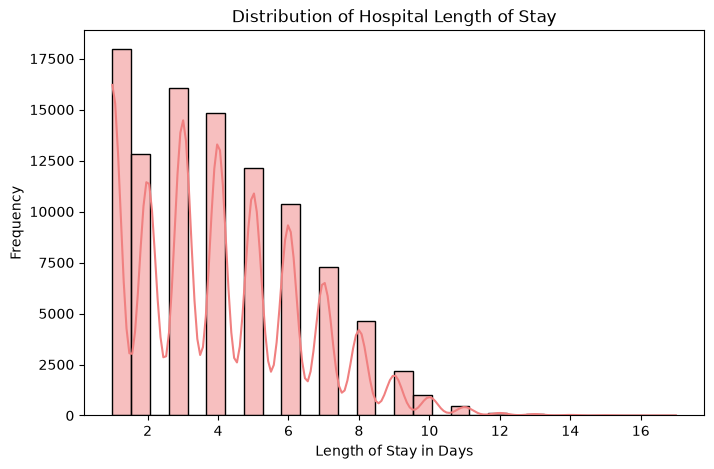

In [14]:
# los distribution
plt.figure(figsize=(8,5))
sns.histplot(df['lengthofstay'], bins=30, kde=True, color='lightcoral')
plt.title("Distribution of Hospital Length of Stay")
plt.xlabel("Length of Stay in Days")
plt.ylabel("Frequency")
plt.show()

## LOS by Gender

C:\Users\ramaseshu\AppData\Local\Temp\ipykernel_28256\3665236923.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='gender', y='lengthofstay', data=df, palette='pastel')


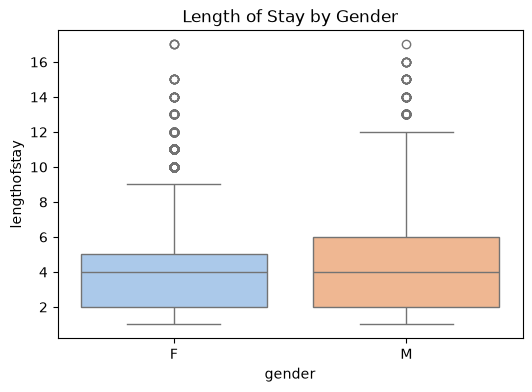

In [15]:
# los by gender
plt.figure(figsize=(6,4))
sns.boxplot(x='gender', y='lengthofstay', data=df, palette='pastel')
plt.title("Length of Stay by Gender")
plt.show()

## LOS by Facility

C:\Users\ramaseshu\AppData\Local\Temp\ipykernel_28256\4039468757.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='facid', y='lengthofstay', data=df, palette='pastel')


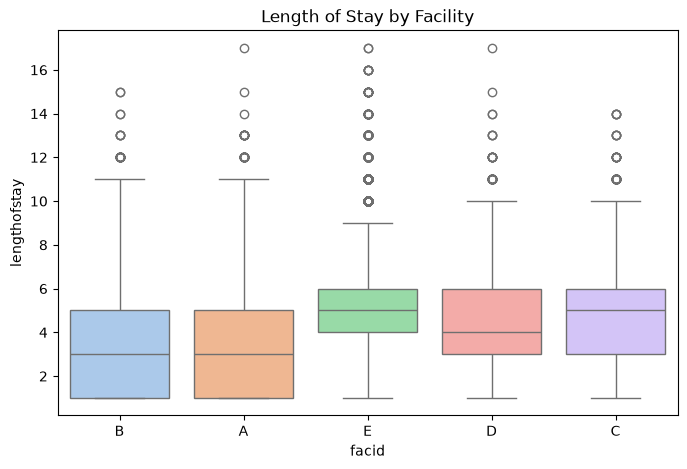

In [16]:
# los by facility
plt.figure(figsize=(8,5))
sns.boxplot(x='facid', y='lengthofstay', data=df, palette='pastel')
plt.title("Length of Stay by Facility")
plt.show()

## Correlation Heatmap

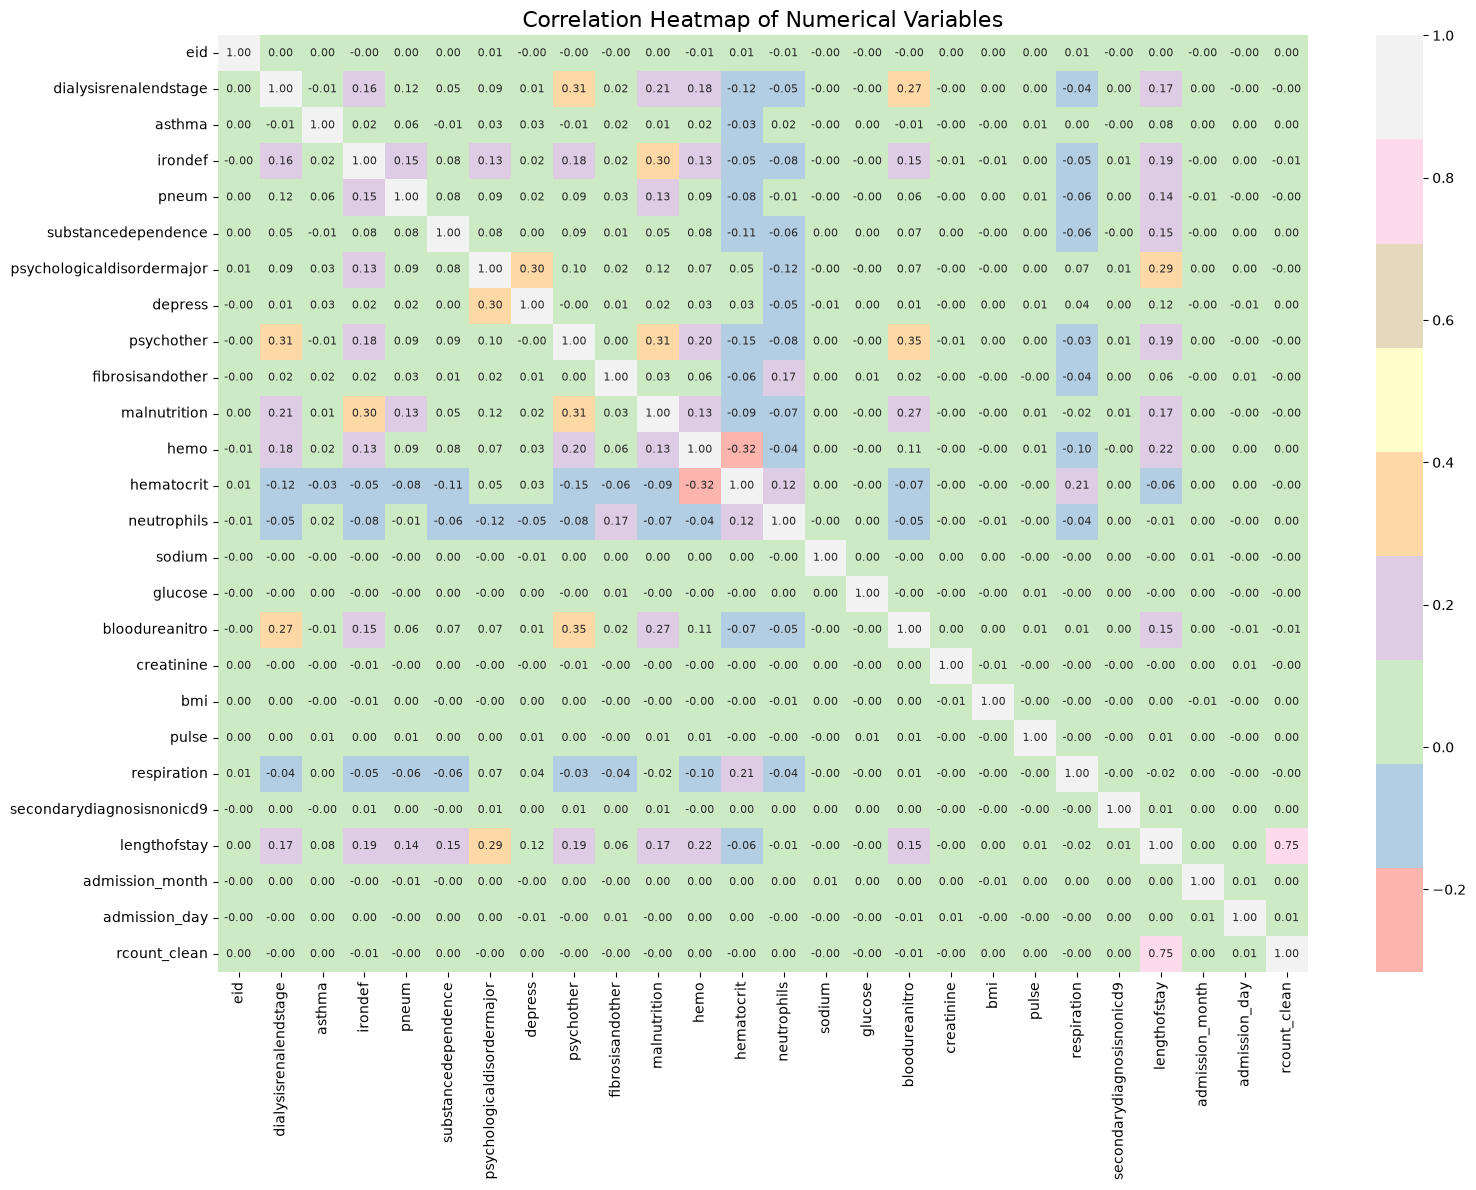

In [17]:
# correlation heatmap
plt.figure(figsize=(16,12))
sns.heatmap(df.select_dtypes(include=np.number).corr(), cmap="Pastel1", annot=True, fmt=".2f", annot_kws={'fontsize':8})
plt.title("Correlation Heatmap of Numerical Variables", fontsize=16)
plt.xticks(rotation=90, ha='center', fontsize=10)
plt.yticks(rotation=0, va='center', fontsize=10)
plt.tight_layout()
plt.show()

In [18]:
# Define Features and Target
df_cleaned = df.dropna(subset=['lengthofstay'])
X = df_cleaned.drop(columns=[
    'lengthofstay',
    'eid',
    'vdate',
    'rcount'
])
y = df_cleaned['lengthofstay']

In [19]:
# Identify Numerical and Categorical Columns
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

Categorical Columns: Index(['gender', 'facid'], dtype='str')
Numerical Columns: Index(['dialysisrenalendstage', 'asthma', 'irondef', 'pneum',
       'substancedependence', 'psychologicaldisordermajor', 'depress',
       'psychother', 'fibrosisandother', 'malnutrition', 'hemo', 'hematocrit',
       'neutrophils', 'sodium', 'glucose', 'bloodureanitro', 'creatinine',
       'bmi', 'pulse', 'respiration', 'secondarydiagnosisnonicd9',
       'rcount_clean'],
      dtype='str')


C:\Users\ramaseshu\AppData\Local\Temp\ipykernel_28256\1824681532.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns


In [20]:
# preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

## Train-Test Split

In [21]:
# training and testing dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape)
print(X_test.shape)

(80000, 26)
(20000, 26)


# Linear Regression

In [22]:
# linear regression model
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

In [23]:
# Calculating Regression Metrics
mse = mean_squared_error(y_test, lr_pred)
mae = mean_absolute_error(y_test, lr_pred)
r2 = r2_score(y_test, lr_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

Mean Squared Error (MSE): 1.2879
Mean Absolute Error (MAE): 0.8664
R-squared (R2 Score): 0.7653


# Decision Tree

In [24]:
# decision tree model
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

In [25]:
# Calculating Regression Metrics for Decision Tree
mse_dt = mean_squared_error(y_test, dt_pred)
mae_dt = mean_absolute_error(y_test, dt_pred)
r2_dt = r2_score(y_test, dt_pred)
print(f"Decision Tree - Mean Squared Error (MSE): {mse_dt:.4f}")
print(f"Decision Tree - Mean Absolute Error (MAE): {mae_dt:.4f}")
print(f"Decision Tree - R-squared (R2 Score): {r2_dt:.4f}")

Decision Tree - Mean Squared Error (MSE): 0.8696
Decision Tree - Mean Absolute Error (MAE): 0.5011
Decision Tree - R-squared (R2 Score): 0.8415


# Random Forest

In [26]:
# random forest model
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [27]:
# Calculating Regression Metrics for Random Forest
mse_rf = mean_squared_error(y_test, rf_pred)
mae_rf = mean_absolute_error(y_test, rf_pred)
r2_rf = r2_score(y_test, rf_pred)
print(f"Random Forest - Mean Squared Error (MSE): {mse_rf:.4f}")
print(f"Random Forest - Mean Absolute Error (MAE): {mae_rf:.4f}")
print(f"Random Forest - R-squared (R2 Score): {r2_rf:.4f}")

Random Forest - Mean Squared Error (MSE): 0.4125
Random Forest - Mean Absolute Error (MAE): 0.3891
Random Forest - R-squared (R2 Score): 0.9248


# Gradient Boosting

In [28]:
# gardient boosting model
gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))
])
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

In [29]:
# calculating metrices
mse_gb = mean_squared_error(y_test, gb_pred)
mae_gb = mean_absolute_error(y_test, gb_pred)
r2_gb = r2_score(y_test, gb_pred)
print(f"Gradient Boosting - Mean Squared Error (MSE): {mse_gb:.4f}")
print(f"Gradient Boosting - Mean Absolute Error (MAE): {mae_gb:.4f}")
print(f"Gradient Boosting - R-squared (R2 Score): {r2_gb:.4f}")

Gradient Boosting - Mean Squared Error (MSE): 0.3593
Gradient Boosting - Mean Absolute Error (MAE): 0.4431
Gradient Boosting - R-squared (R2 Score): 0.9345


# Deep Learning Model: ANN

In [30]:
# deep learning model- ANN
ann_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=300,
        random_state=42
    ))
])
ann_model.fit(X_train, y_train)
ann_pred = ann_model.predict(X_test)

c:\Users\ramaseshu\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [31]:
# evaluating metrices
def evaluate_model(model_name, y_test, y_pred):
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    return {
        "Model": model_name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    }

In [32]:
#  ANN model and print the results
ann_metrics = evaluate_model("ANN", y_test, ann_pred)
print("ANN Model Evaluation Metrics:")
for metric, value in ann_metrics.items():
    if isinstance(value, (int, float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

ANN Model Evaluation Metrics:
Model: ANN
MSE: 0.1949
RMSE: 0.4415
MAE: 0.2963
R2 Score: 0.9645


# Compare All Models

In [33]:
# comparing results
results = []
results.append(evaluate_model("Linear Regression", y_test, lr_pred))
results.append(evaluate_model("Decision Tree", y_test, dt_pred))
results.append(evaluate_model("Random Forest", y_test, rf_pred))
results.append(evaluate_model("Gradient Boosting", y_test, gb_pred))
results.append(evaluate_model("ANN", y_test, ann_pred))
results_df = pd.DataFrame(results)
results_df_formatted = results_df.round(4)
print(results_df_formatted)

               Model     MSE    RMSE     MAE  R2 Score
0  Linear Regression  1.2879  1.1348  0.8664    0.7653
1      Decision Tree  0.8696  0.9325  0.5011    0.8415
2      Random Forest  0.4125  0.6422  0.3891    0.9248
3  Gradient Boosting  0.3593  0.5994  0.4431    0.9345
4                ANN  0.1949  0.4415  0.2963    0.9645


C:\Users\ramaseshu\AppData\Local\Temp\ipykernel_28256\1751719749.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y="RMSE", data=results_df, palette='Paired')


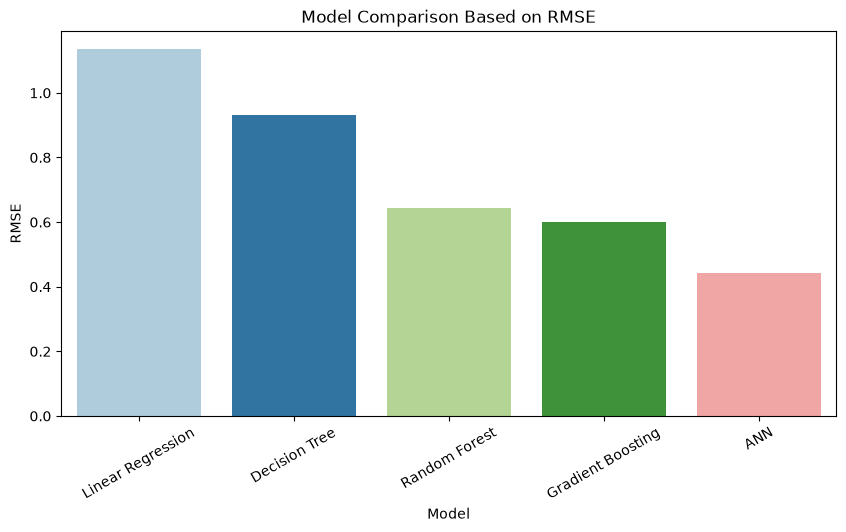

In [34]:
# Visualising Model Performance
plt.figure(figsize=(10,5))
sns.barplot(x="Model", y="RMSE", data=results_df, palette='Paired')
plt.title("Model Comparison Based on RMSE")
plt.xticks(rotation=30)
plt.show()

In [35]:
# Cross-Validation
cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='neg_root_mean_squared_error'
)
print("Random Forest CV RMSE Scores:", -cv_scores)
print("Average CV RMSE:", -cv_scores.mean())

Random Forest CV RMSE Scores: [0.64558857 0.66147934 0.65815347 0.64794134 0.65552995]
Average CV RMSE: 0.6537385356271083


In [36]:
# Hyperparameter Tuning
param_grid = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5]
}
grid_search = GridSearchCV(
    rf_model,
    param_grid,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
print("Best Parameters:", grid_search.best_params_)
print("Best RMSE:", -grid_search.best_score_)

Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best RMSE: 0.6786189503128203


In [37]:
# model selection
best_model = grid_search.best_estimator_
final_pred = best_model.predict(X_test)
final_results = evaluate_model("Tuned Random Forest", y_test, final_pred)
print(final_results)

{'Model': 'Tuned Random Forest', 'MSE': 0.4115504193496234, 'RMSE': np.float64(0.6415219554696654), 'MAE': 0.38871594644383395, 'R2 Score': 0.9249980518102755}


In [38]:
# Actual vs Predicted LOS
comparison_df = pd.DataFrame({
    "Actual LOS": y_test.values,
    "Predicted LOS": final_pred
})
print(comparison_df.head(20))

    Actual LOS  Predicted LOS
0            4       3.813667
1            1       1.000000
2            2       2.789452
3            1       1.000000
4            5       5.215000
5            1       1.000000
6            2       1.766044
7            3       3.092512
8            4       5.147413
9            2       3.153095
10           8       8.151556
11           1       1.020000
12           6       5.272988
13           3       3.046833
14           1       1.080333
15           3       3.000000
16           4       4.022500
17           3       3.389333
18           1       3.509893
19           4       4.051155


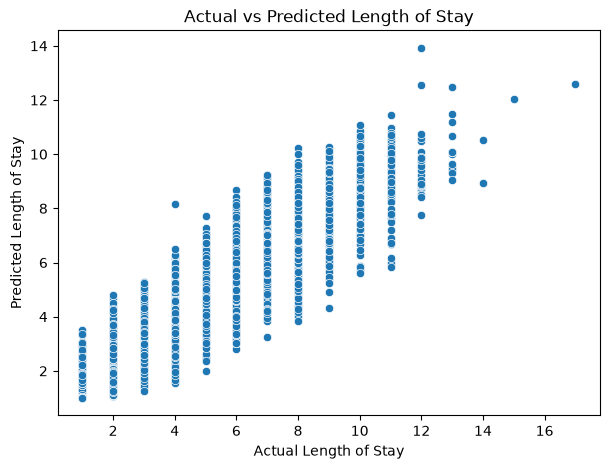

In [39]:
# visualisation
plt.figure(figsize=(7,5))
sns.scatterplot(x=y_test, y=final_pred)
plt.xlabel("Actual Length of Stay")
plt.ylabel("Predicted Length of Stay")
plt.title("Actual vs Predicted Length of Stay")
plt.show()

In [40]:
# Operational Decision Interpretation
comparison_df['Risk_Level'] = comparison_df['Predicted LOS'].apply(
    lambda x: 'High Bed/Staff Demand' if x >= 7 else 'Normal Bed/Staff Demand'
)

print(comparison_df.head(20))

    Actual LOS  Predicted LOS               Risk_Level
0            4       3.813667  Normal Bed/Staff Demand
1            1       1.000000  Normal Bed/Staff Demand
2            2       2.789452  Normal Bed/Staff Demand
3            1       1.000000  Normal Bed/Staff Demand
4            5       5.215000  Normal Bed/Staff Demand
5            1       1.000000  Normal Bed/Staff Demand
6            2       1.766044  Normal Bed/Staff Demand
7            3       3.092512  Normal Bed/Staff Demand
8            4       5.147413  Normal Bed/Staff Demand
9            2       3.153095  Normal Bed/Staff Demand
10           8       8.151556    High Bed/Staff Demand
11           1       1.020000  Normal Bed/Staff Demand
12           6       5.272988  Normal Bed/Staff Demand
13           3       3.046833  Normal Bed/Staff Demand
14           1       1.080333  Normal Bed/Staff Demand
15           3       3.000000  Normal Bed/Staff Demand
16           4       4.022500  Normal Bed/Staff Demand
17        